# Persistence Baseline and Linear Regression

Forecast objective: predict `target_appliances_next` 10 minutes after the feature-row timestamp. Persistence is a meaningful short-horizon baseline: it assumes the next energy reading equals current `Appliances`.

Linear Regression uses the ordered features in `feature_schema.json`. A `StandardScaler` is fitted as part of a Pipeline on training rows only, then the fitted pipeline predicts validation rows. MAE, RMSE, and R² below are validation metrics only. The TEST set is not loaded, inspected, predicted, or evaluated. No tuning or model saving is performed.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

candidate_roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in candidate_roots if (p / 'ml/src/train_baselines.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate ml/src/train_baselines.py')
sys.path.insert(0, str(PROJECT_ROOT))
from ml.src.train_baselines import run_phase7
report, artifacts = run_phase7()
print('Evaluation split:', report['evaluation_split'])
print('Train rows / validation rows / features:', report['train_rows'], report['validation_rows'], report['feature_count'])
print('StandardScaler fitted on:', report['scaler_fit_split'], 'rows:', report['scaler_fit_rows'])
print('Test set was not loaded or evaluated in Phase 7.')
print('Validation metrics written to:', report['results_path'])

Evaluation split: validation
Train rows / validation rows / features: 13108 2809 42
StandardScaler fitted on: train rows: 13108
Test set was not loaded or evaluated in Phase 7.
Validation metrics written to: C:\Users\arbak\Projects\SmartEnergyAI\ml\results\phase7_validation_metrics.json


## Validation Metrics and Comparison

Persistence predictions are the validation rows' current `Appliances` values. Linear Regression is fitted only on training data. Lower MAE/RMSE and higher R² indicate better validation metrics; RMSE is the primary Phase 7 comparison criterion. This is not final thesis model selection.

,MAE,RMSE,R²
Persistence Baseline,25.920256,65.794972,0.465273
Linear Regression,27.025294,59.346237,0.564956


Best Phase 7 model by validation RMSE: Linear Regression
Linear Regression RMSE improvement over persistence (%): 9.801257070169457
Actual vs Predicted period: first 7 contiguous validation days, 2016-04-18 17:40:00 through 2016-04-25 17:30:00 (1008 observations)


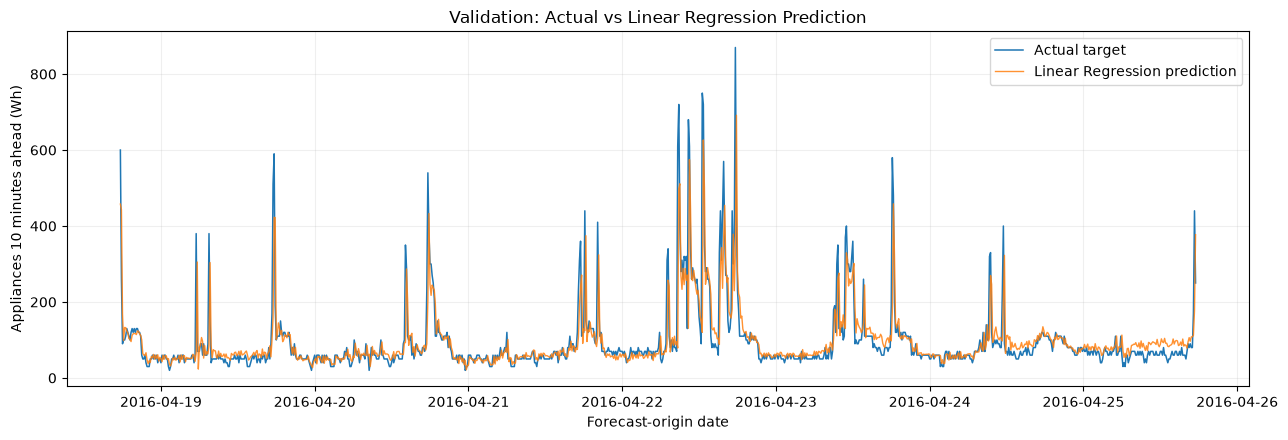

In [2]:
comparison = pd.DataFrame.from_dict(report['models'], orient='index')
comparison = comparison.rename(columns={'mae': 'MAE', 'rmse': 'RMSE', 'r2': 'R²'})
display(comparison)
print('Best Phase 7 model by validation RMSE:', report['best_validation_model_by_rmse'])
print('Linear Regression RMSE improvement over persistence (%):', report['linear_regression_rmse_improvement_percent'])
validation_dates = artifacts['validation_dates']
window_end = validation_dates.iloc[0] + pd.Timedelta(days=7)
window_mask = validation_dates < window_end
window_dates = validation_dates.loc[window_mask]
actual_window = artifacts['actual'].loc[window_mask]
prediction_window = artifacts['linear_regression_predictions'].loc[window_mask]
print(f'Actual vs Predicted period: first 7 contiguous validation days, {window_dates.iloc[0]} through {window_dates.iloc[-1]} ({len(window_dates)} observations)')
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(window_dates, actual_window, label='Actual target', linewidth=1.1)
ax.plot(window_dates, prediction_window, label='Linear Regression prediction', linewidth=1.0, alpha=0.85)
ax.set(title='Validation: Actual vs Linear Regression Prediction', xlabel='Forecast-origin date', ylabel='Appliances 10 minutes ahead (Wh)')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Residuals and Limitations

Residuals are defined as actual validation target minus Linear Regression prediction. The plots and summary are validation-only diagnostics; no observations are removed. The model is unregularized and untuned, the data cover one chronological collection, and correlations/features are not causal claims. The test partition remains reserved for one final evaluation after later model selection.

Validation residual summary (actual - predicted):


count    2809.000000
mean       -0.658612
std        59.353148
min      -306.669980
25%       -18.311963
50%        -5.889057
75%         5.447677
max       629.785695
dtype: float64

Mean validation residual: -0.6586121344696475


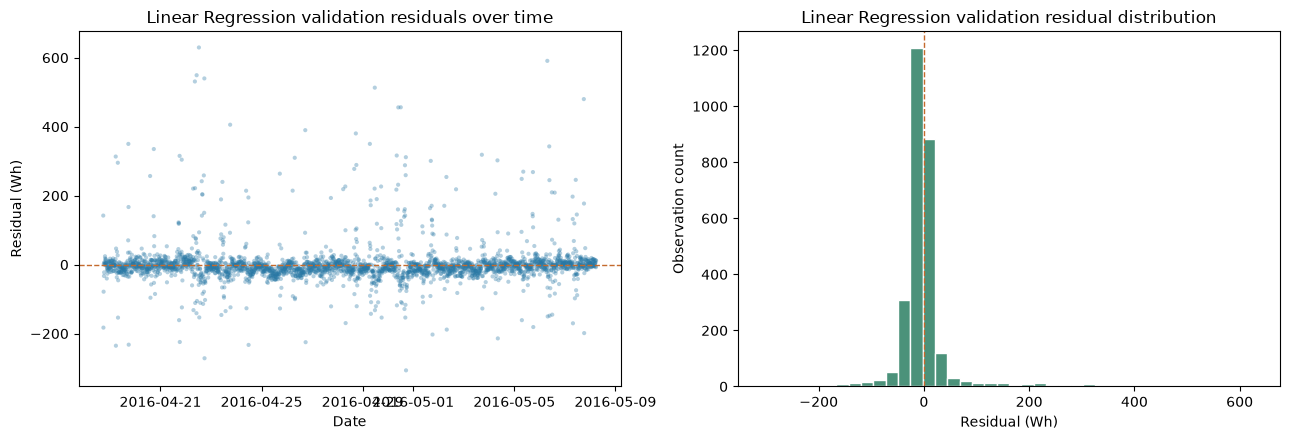

In [3]:
residuals = artifacts['linear_regression_residuals']
print('Validation residual summary (actual - predicted):')
display(residuals.describe())
print('Mean validation residual:', float(residuals.mean()))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(validation_dates, residuals, s=9, alpha=0.35, color='#2878A5', edgecolors='none')
axes[0].axhline(0, color='#C46A2D', linestyle='--', linewidth=1)
axes[0].set(title='Linear Regression validation residuals over time', xlabel='Date', ylabel='Residual (Wh)')
axes[1].hist(residuals, bins=40, color='#4B927A', edgecolor='white')
axes[1].axvline(0, color='#C46A2D', linestyle='--', linewidth=1)
axes[1].set(title='Linear Regression validation residual distribution', xlabel='Residual (Wh)', ylabel='Observation count')
fig.tight_layout()
plt.show()
assert report['scaler_fit_split'] == 'train' and report['scaler_fit_rows'] == report['train_rows']
assert report['test_set_accessed'] is False